In [1]:
import torch
import torch.optim as optim
from torch.utils.data import DataLoader
import numpy as np

from utils.phase import Phase
from utils.model_utils import criterion_to_str
from utils.model_utils import compare_results_strata
from data_augmentation.monte_carlo_loader import MonteCarloLoader
from data_augmentation.datasets.dense_monte_carlo_dataset import DenseMonteCarloDataset
from model.architecture.dense_monte_carlo import DenseMonteCarloNet
from model.architecture.residual_connection_dense import ResDeepAHPNet
from model.loss_function.dense_monte_carlo.custom_dense_MC_loss import CustomDenseMCLoss
from model.model_loader import ModelLoader
from model.trainers.dense_monte_carlo_trainer import DenseMonteCarloTrainer
from analytic_methods.EVM_method import EVM
from visualization.results.metrics_visualizator import MetricsVisualizator
from visualization.data.weights_visualizator import WeightsVisualizator
from metrics.evaluator import Evaluator

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device used: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Device used: cuda
GPU: NVIDIA GeForce RTX 2060


In [2]:
CRITERIA_NUM = 5
CRITERIA_NUMS = [3, 4, 5, 6, 7, 8, 9]
STRATA = ['low_inconsistency', 'moderate_inconsistency', 'high_inconsistency']
TRAIN_MATRICES_NUM = None
VALID_MATRICES_NUM = None
TEST_MATRICES_NUM = None

BATCH_SIZE = 1024
LEARNING_RATE = 5e-4
NORMALIZE_INITIAL_LOSS = False # dopisać o tym w pracy 
COP = 0.5
FIT = 0.45
STAB = 0.05
P = 2 # 1 = MAE, 2 = MSE
MARGIN = 0.05
EPOCHS = 500
COP_MODE = "margin" 
STAB_MODE = "kullback"
    # COP, FIT, STAB, P, MARGIN, NORMALIZE
PARAMETERS = [
    [0.5, 0.45, 0.05, 1, 0.05, True, "margin", "kullback"],
    [0.5, 0.45, 0.05, 1, 0.05, False, "margin", "kullback"],
    [0.5, 0.45, 0.05, 2, 0.05, False, "margin", "kullback"],
    [0.7, 0.25, 0.05, 1, 0.05, True, "margin", "kullback"],
]

criterion_str = criterion_to_str(COP, FIT, STAB, MARGIN, P, COP_MODE, STAB_MODE, NORMALIZE_INITIAL_LOSS)
model_loader = ModelLoader()
empty_model = DenseMonteCarloNet(n_criteria=CRITERIA_NUM)
model, history = model_loader.load_dense_MC(empty_model, CRITERIA_NUM, criterion_str)
criterion = CustomDenseMCLoss(n_criteria=CRITERIA_NUM, lambda_cop=COP, lambda_fit=FIT, lambda_stab=STAB, p=P, 
    normalize_initial_loss=NORMALIZE_INITIAL_LOSS, margin=MARGIN).to(device)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
trainer = DenseMonteCarloTrainer(model, optimizer, criterion, device)

History and model: cop50m_fit45_stab5k_margin5_p2 loaded from models\dense_monte_carlo\criteria5


In [3]:
loader = MonteCarloLoader()
max_test_per_stratum = TEST_MATRICES_NUM // len(STRATA) if TEST_MATRICES_NUM else None

matrices = {}
weights = {}
predicted_priority_weights = {}
evm_solver = EVM()
evm_priority_weights = {}

for stratum in STRATA:
    test_mats, test_wts = loader.load_stratum(
        phase=Phase.TEST,
        num_criteria=CRITERIA_NUM,
        stratum=stratum,
        max_count=max_test_per_stratum
    )
    matrices[stratum] = test_mats
    weights[stratum] = test_wts
    predicted_priority_weights[stratum] = trainer.predict_batch(test_mats)
    evm_pw, _ = evm_solver.compute_batch(test_mats)
    evm_priority_weights[stratum] = evm_pw

print("Predicted AHP weights for all strata.")

Predicted AHP weights for all strata.


In [4]:
# weights_visualizator = WeightsVisualizator()
# nn_name = f"Dense Monte Carlo (N={CRITERIA_NUM})"

# for stratum_key in weights.keys():
#     pred_weights_vector = predicted_priority_weights[stratum_key][0]
#     evm_weights_vector = evm_priority_weights[stratum_key][0].flatten()
#     weights_vector = weights[stratum_key][0].flatten()
#     weights_visualizator.plot_comparison_all(weights_vector, pred_weights_vector, evm_weights_vector, consistency_level=str(stratum_key).split("_")[0], nn_name=nn_name)

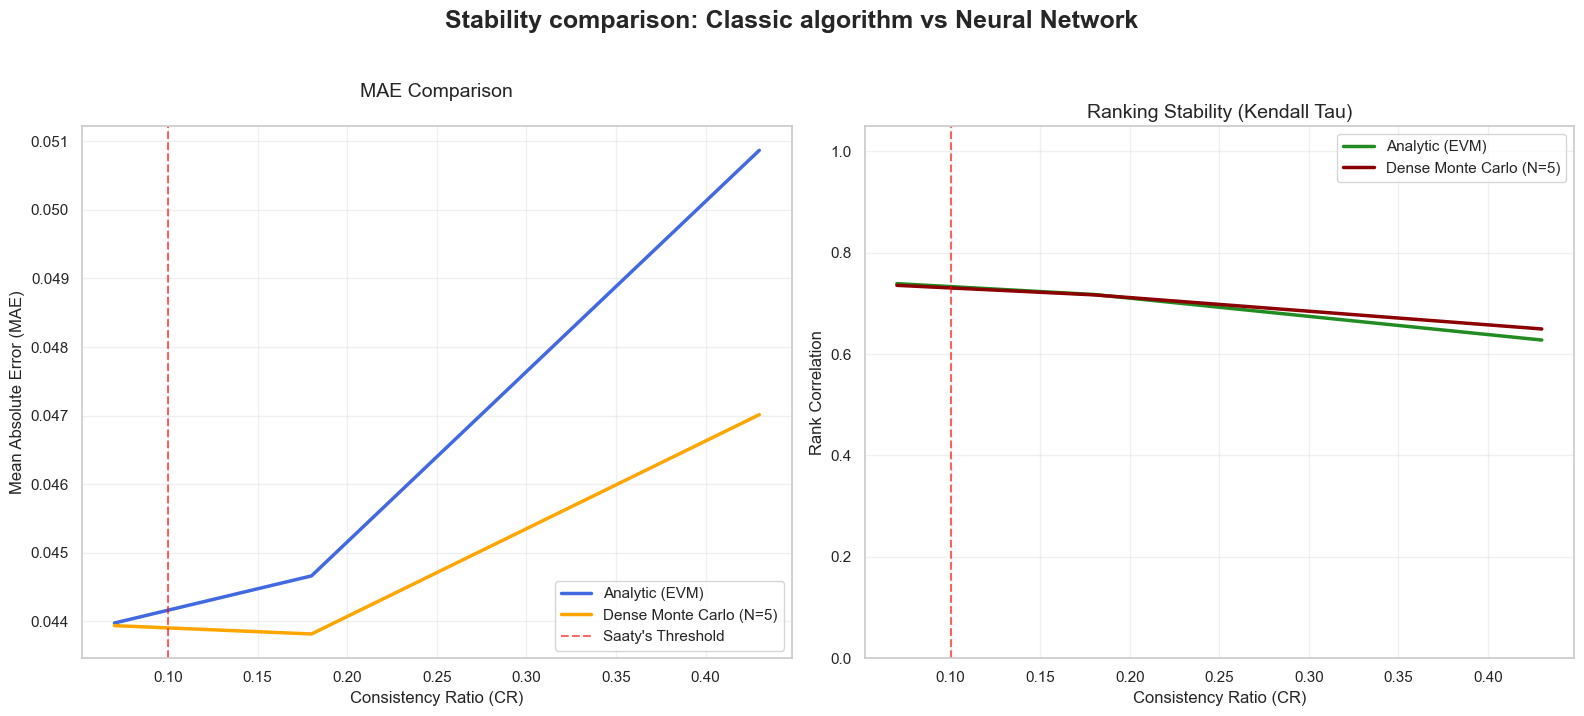

In [5]:
evm_solver = EVM()
evaluator = Evaluator()
nn_name = f"Dense Monte Carlo (N={CRITERIA_NUM})"

compare_results_strata(evm_solver, evaluator, matrices, weights, predicted_priority_weights, nn_name)

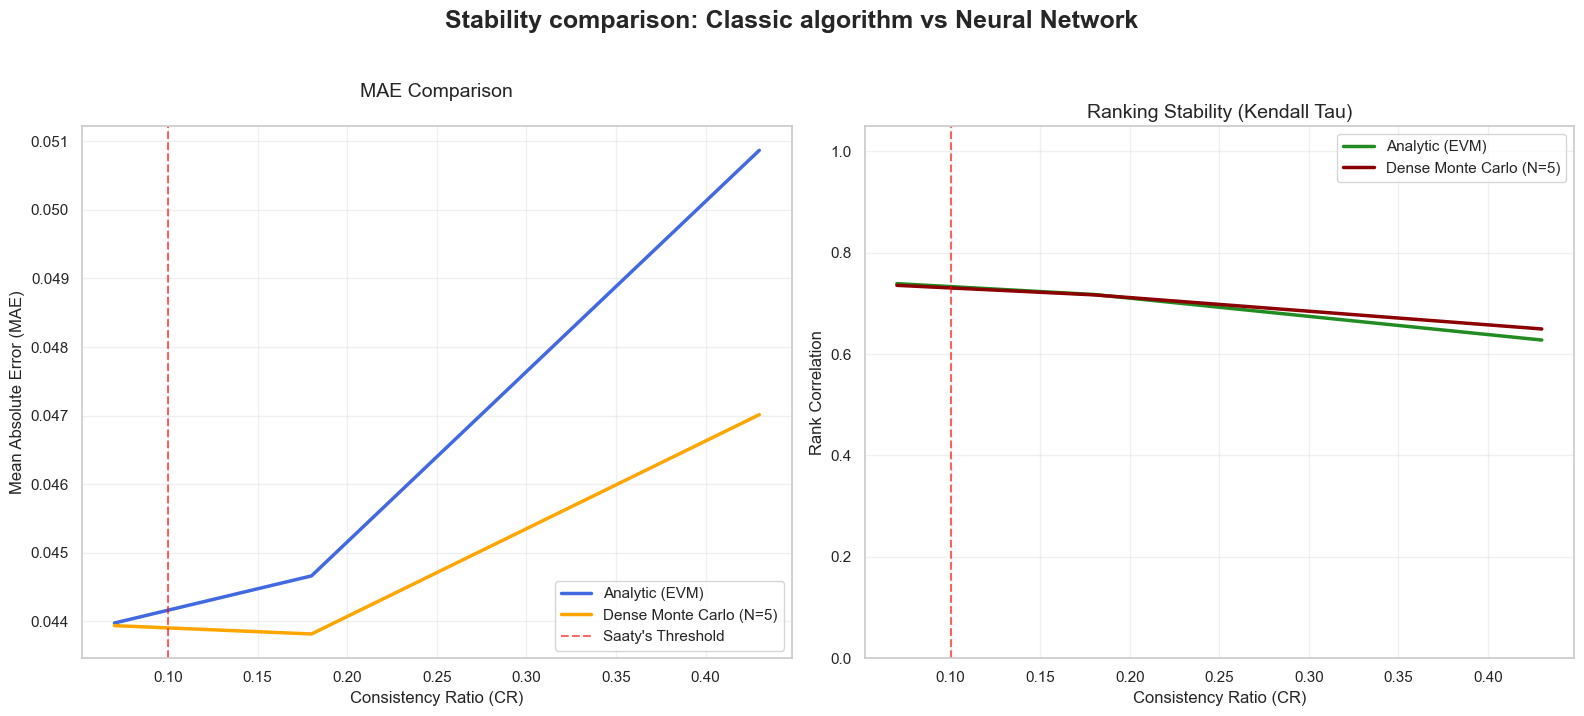

In [6]:
evm_solver = EVM()
evaluator = Evaluator()
nn_name = f"Dense Monte Carlo (N={CRITERIA_NUM})"

compare_results_strata(evm_solver, evaluator, matrices, weights, predicted_priority_weights, nn_name)

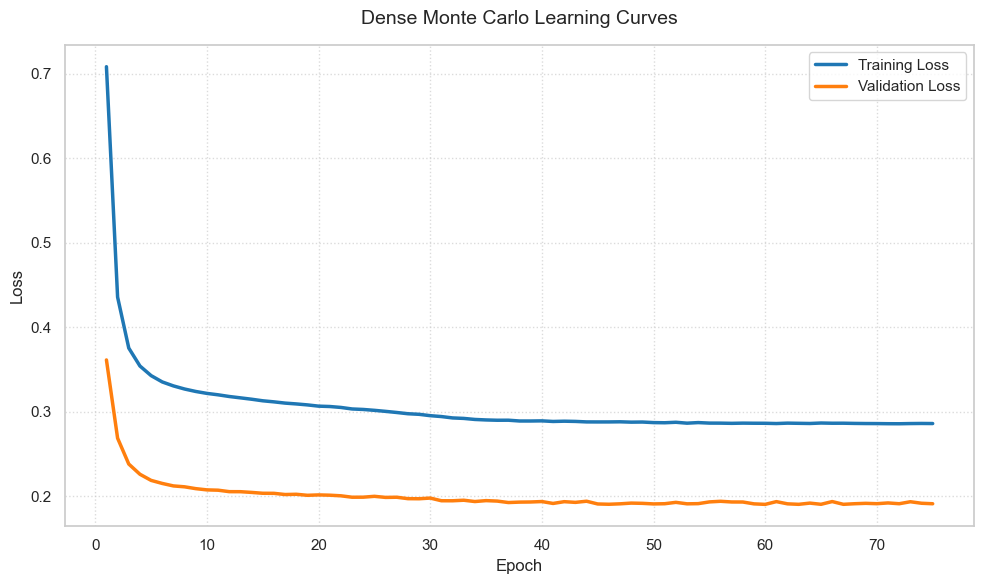

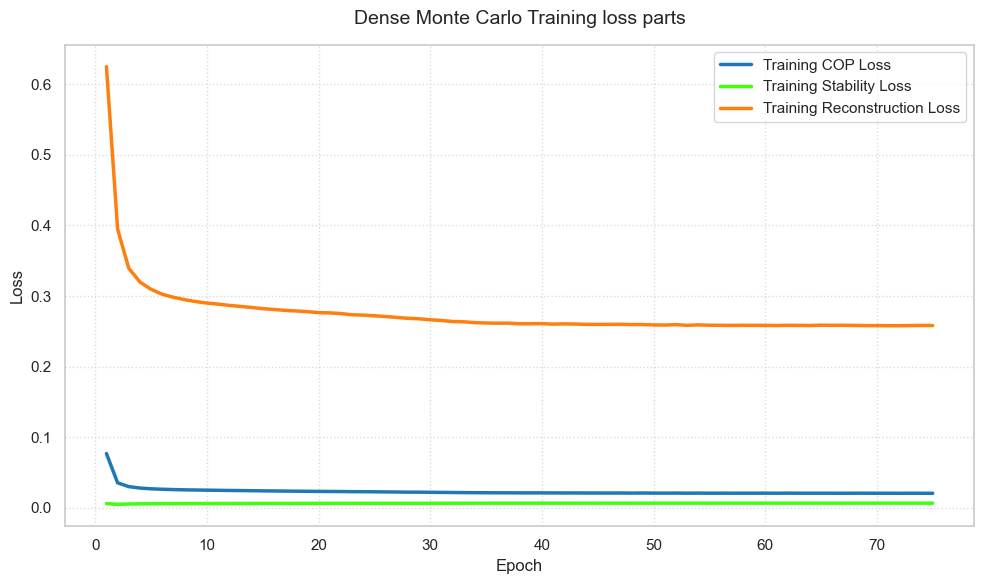

In [7]:
viz = MetricsVisualizator()
viz.display_loss(history, "Dense Monte Carlo")
viz.display_part_losses(history, "Dense Monte Carlo")

## Compare

History and model: cop50m_fit45_stab5k_margin5_p1_initnorm loaded from models\dense_monte_carlo\criteria5


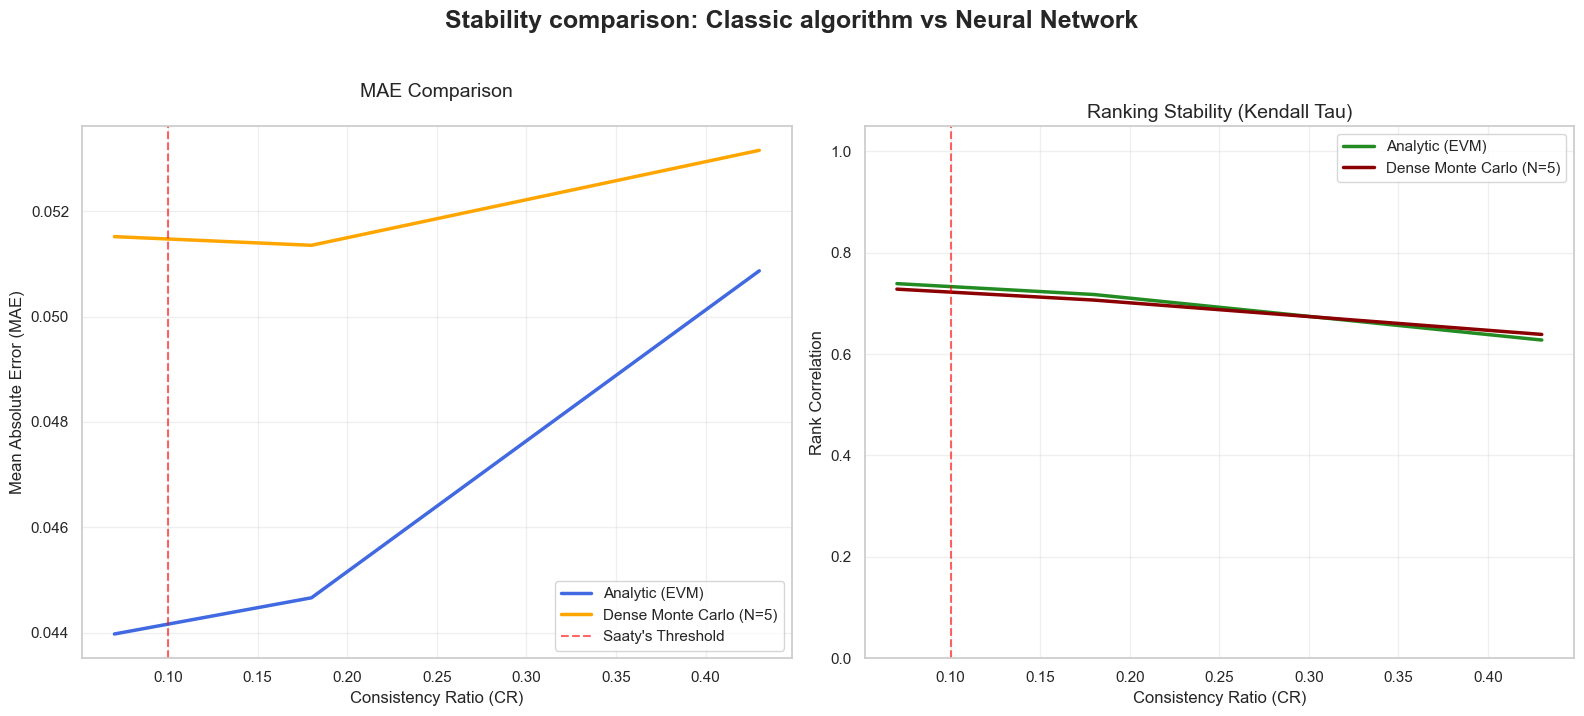

History and model: cop50m_fit45_stab5k_margin5_p1 loaded from models\dense_monte_carlo\criteria5


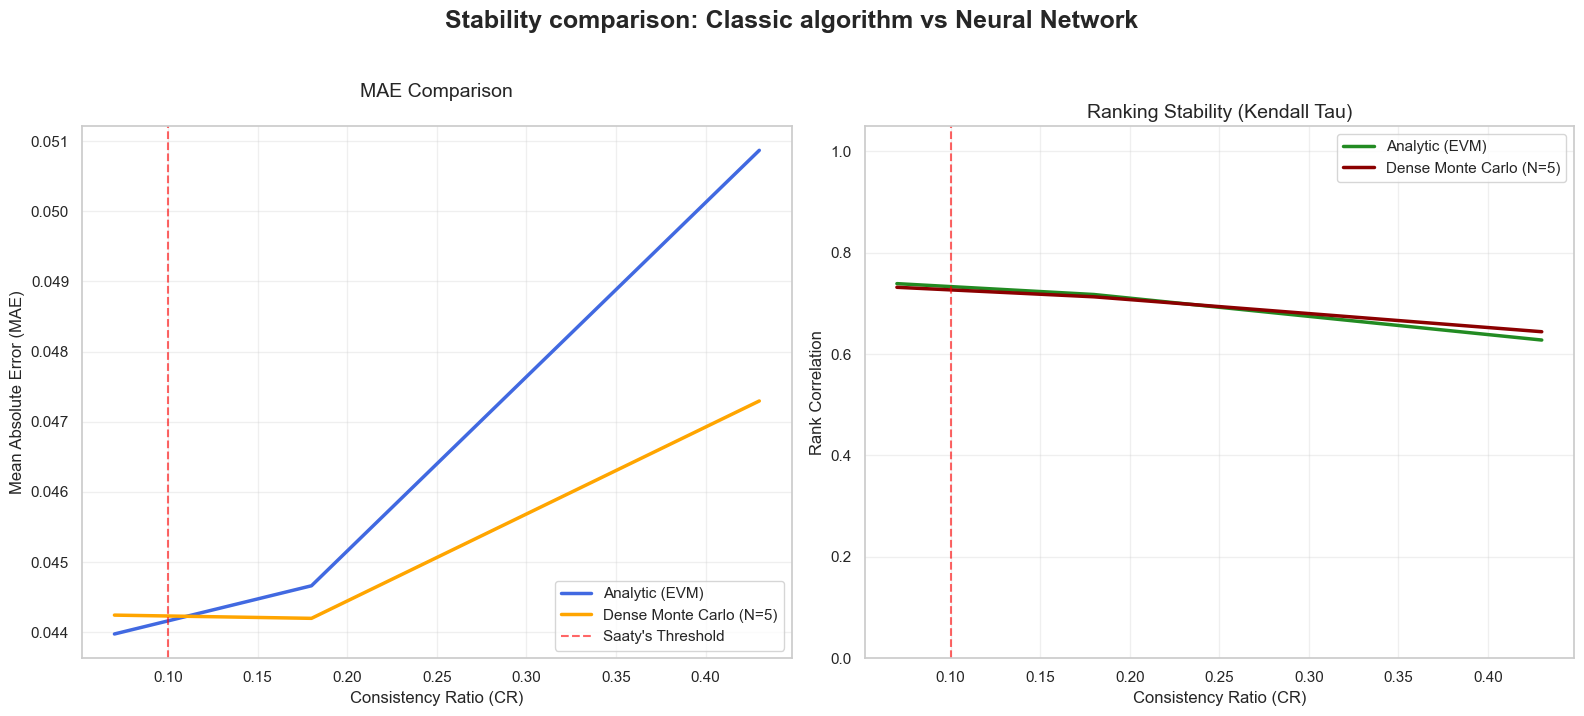

History and model: cop50m_fit45_stab5k_margin5_p2 loaded from models\dense_monte_carlo\criteria5


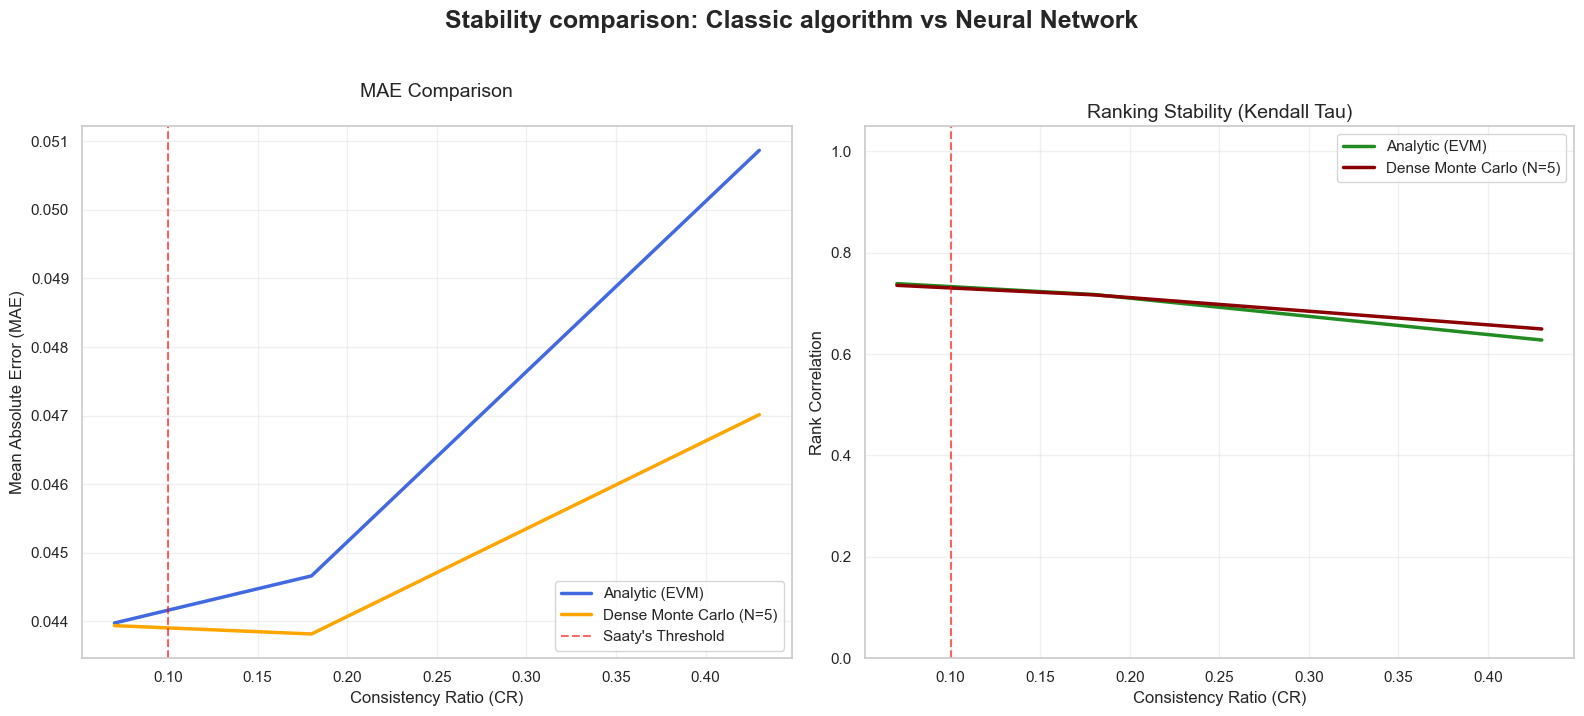

History and model: cop70m_fit25_stab5k_margin5_p1_initnorm loaded from models\dense_monte_carlo\criteria5


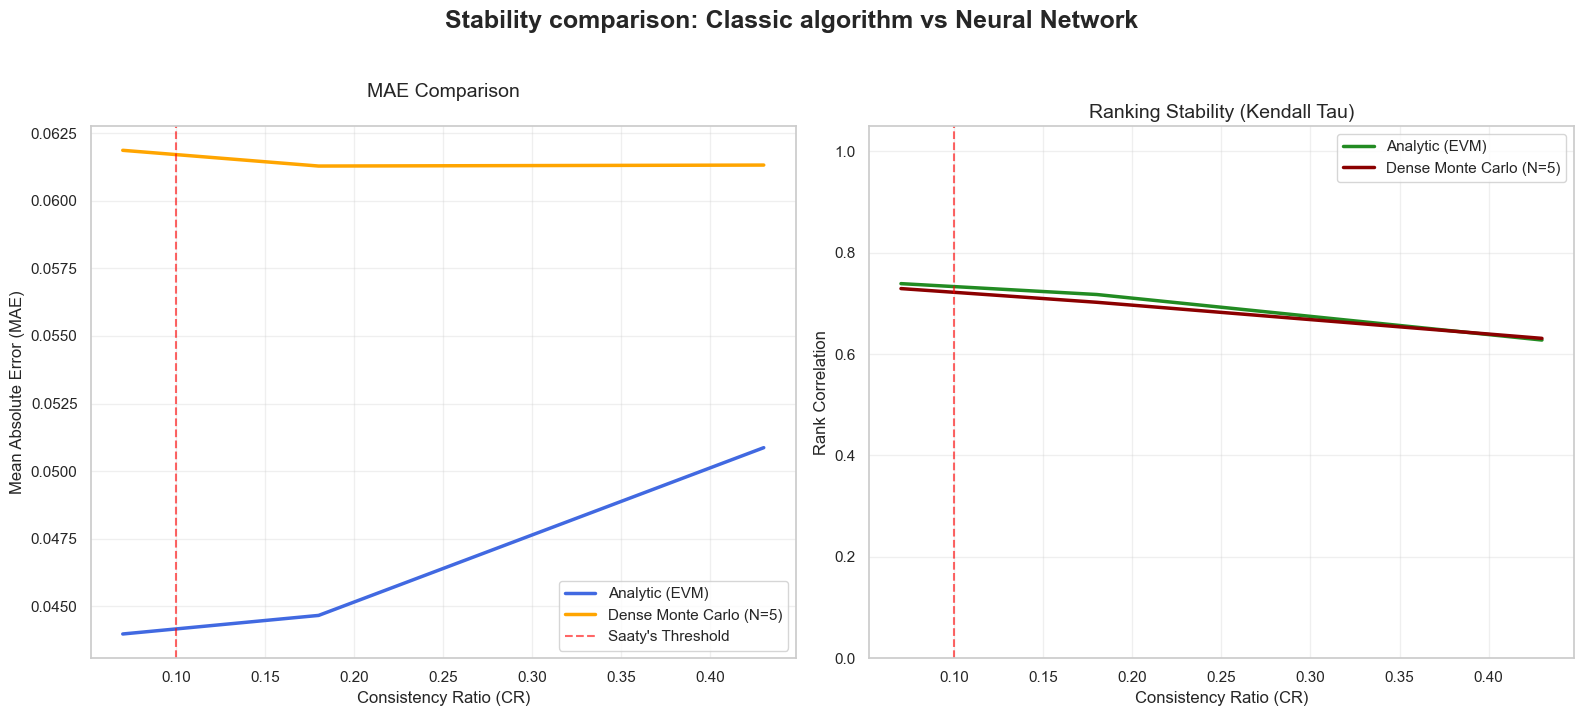

History and model: cop45m_fit40_stab15k_margin5_p1 loaded from models\dense_monte_carlo\criteria5


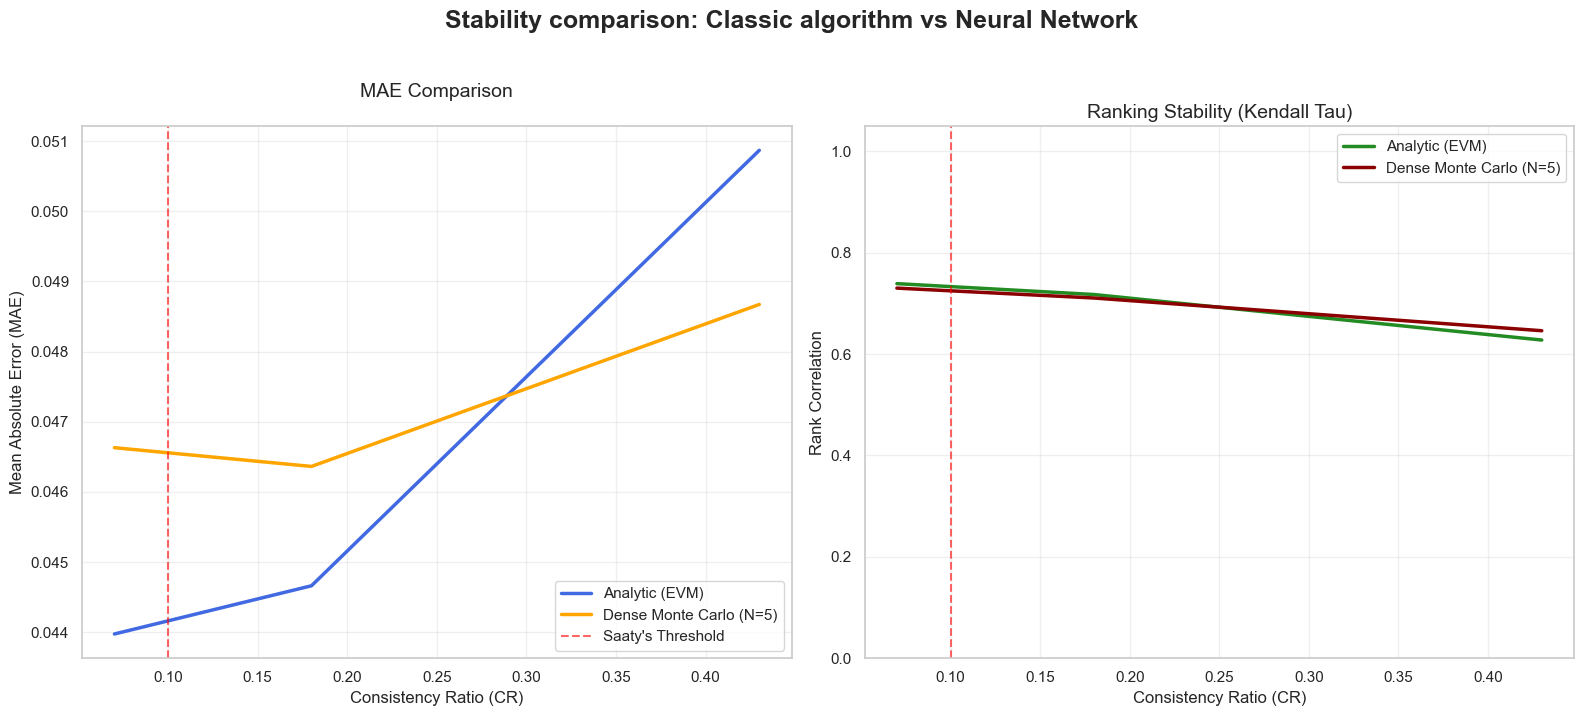

History and model: cop45m_fit40_stab15k_margin5_p1_initnorm loaded from models\dense_monte_carlo\criteria5


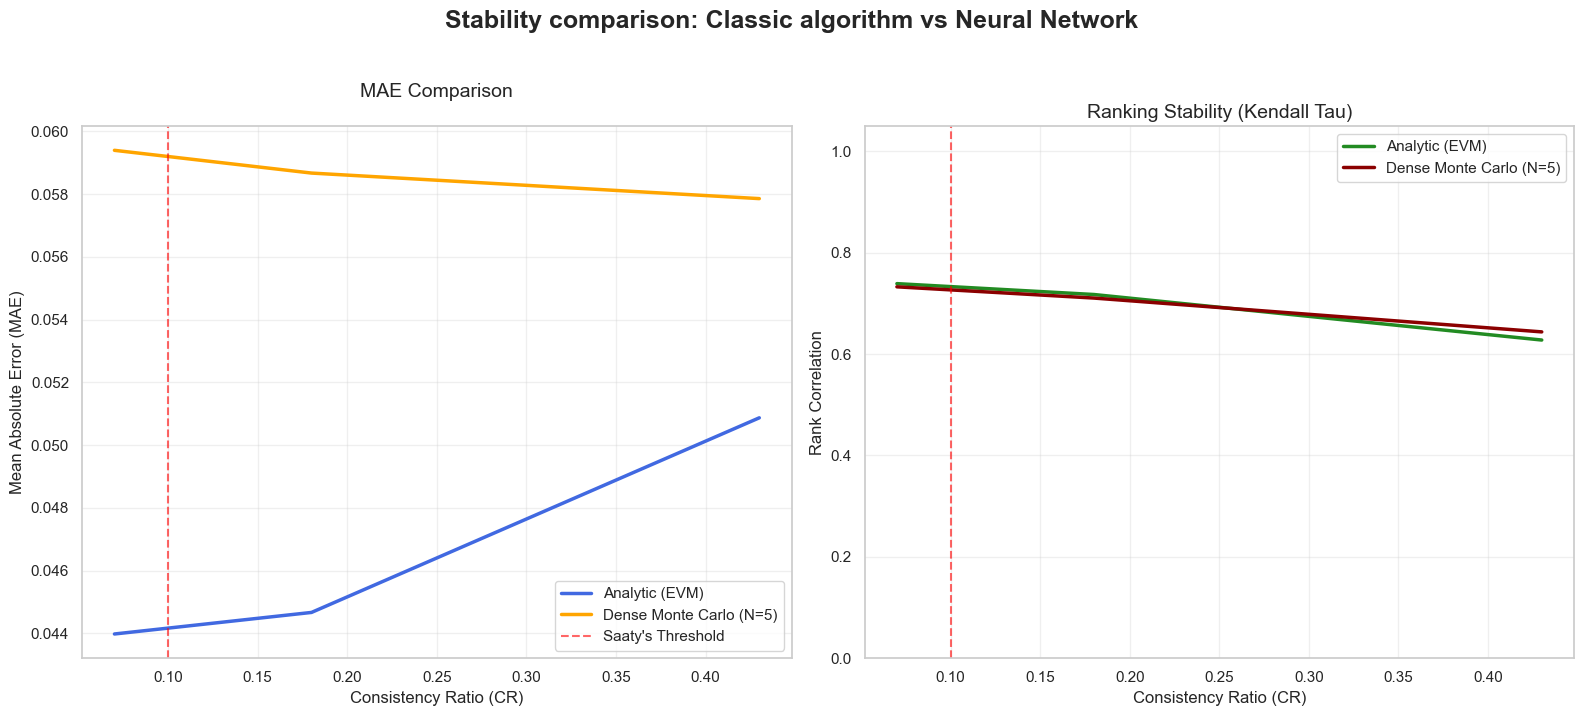

History and model: cop70m_fit25_stab5k_margin5_p2 loaded from models\dense_monte_carlo\criteria5


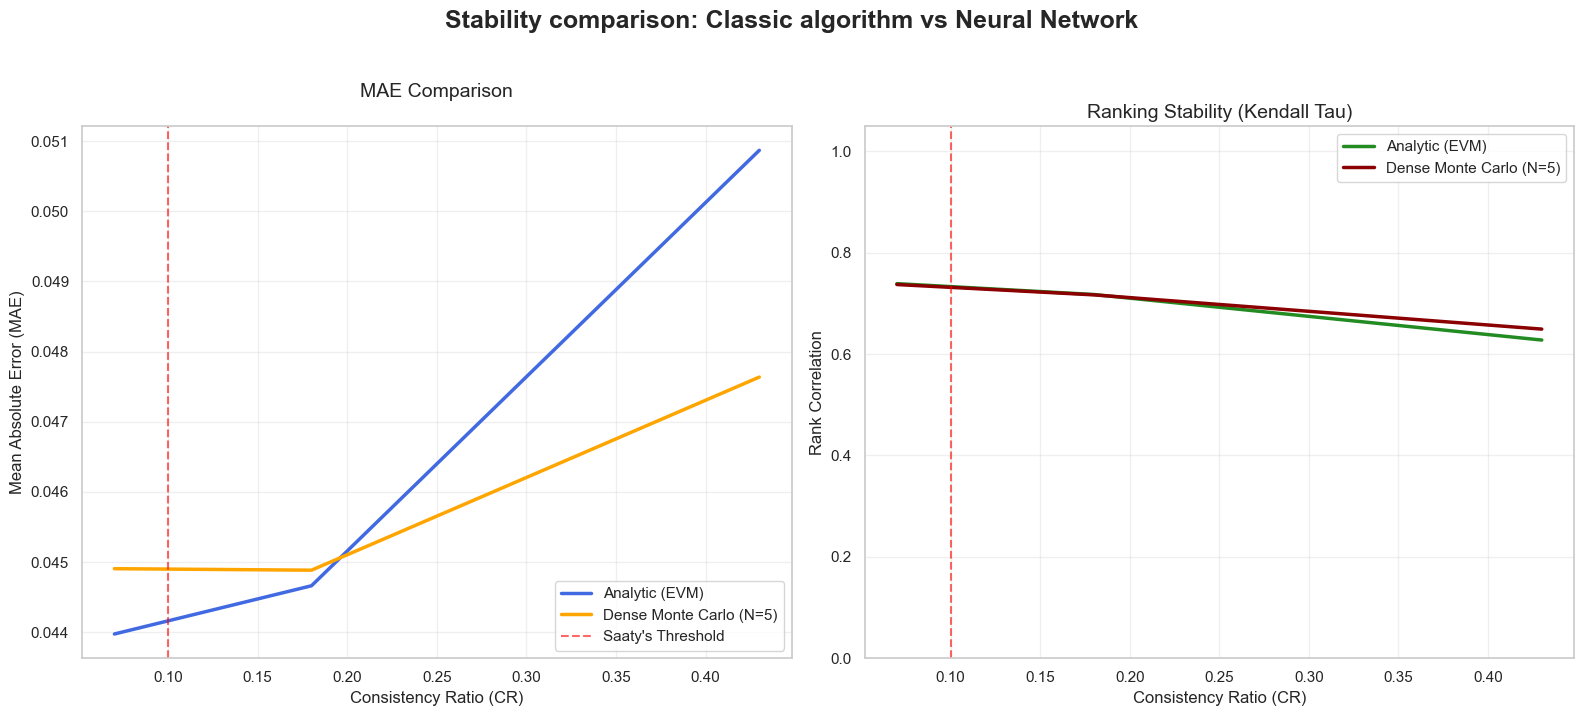

History and model: cop25m_fit70_stab5k_margin5_p2 loaded from models\dense_monte_carlo\criteria5


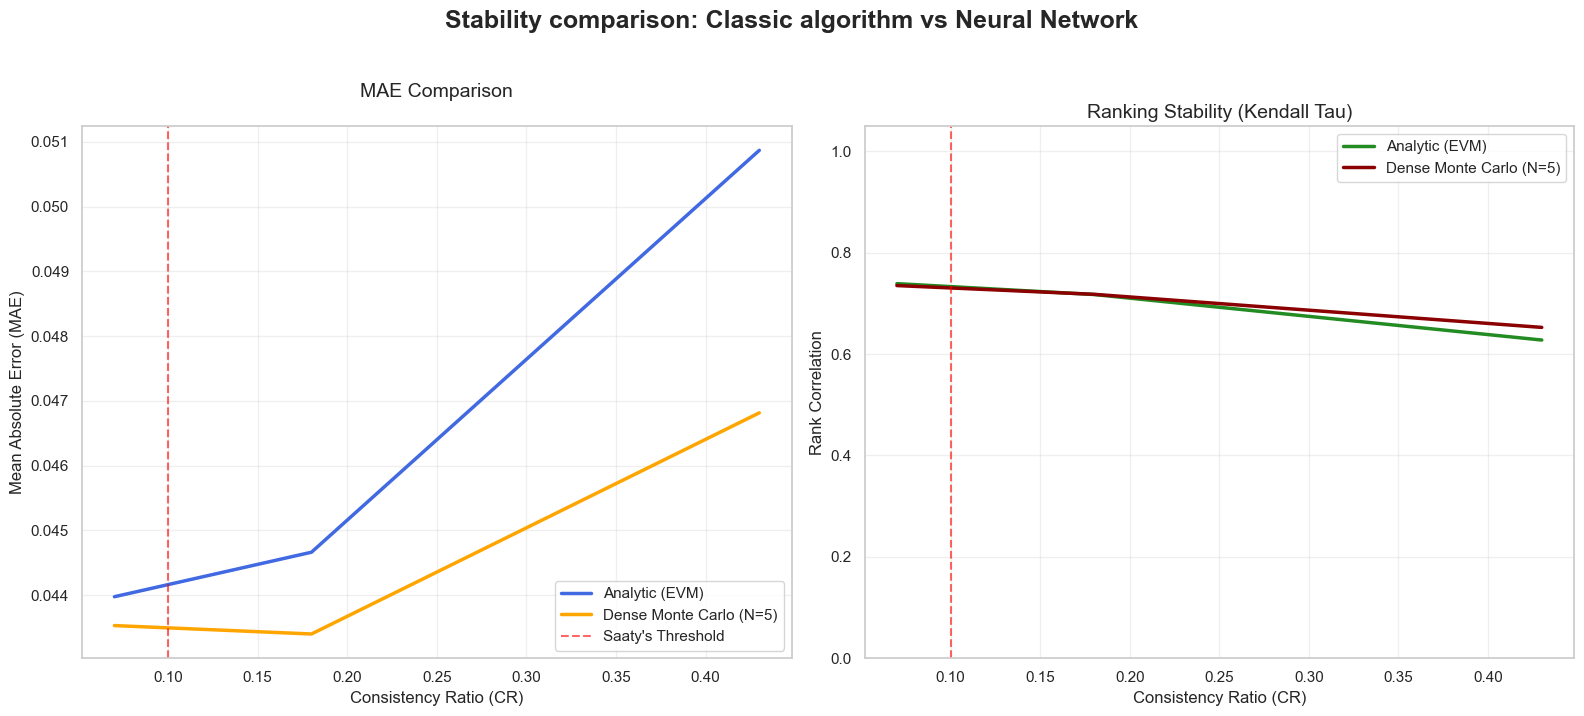

In [ ]:
CRITERIA_NUM = 5
CRITERIA_NUMS = [3, 4, 5, 6, 7, 8, 9]
STRATA = ['low_inconsistency', 'moderate_inconsistency', 'high_inconsistency']
TRAIN_MATRICES_NUM = None
VALID_MATRICES_NUM = None
TEST_MATRICES_NUM = None

BATCH_SIZE = 1024
LEARNING_RATE = 5e-4
    # COP, FIT, STAB, P, MARGIN, NORMALIZE
PARAMETERS = [
    [0.34, 0.33, 0.33, 1, 0.5, True, "margin", "kullback"],
    [0.4, 0.5, 0.1, 1, 0.5, True, "margin", "kullback"],
    [2, 3, 0.5, 1, 0.5, False, "margin", "kullback"],
    [0.5, 0.45, 0.05, 1, 0.05, True, "margin", "kullback"],
    [0.5, 0.45, 0.05, 1, 0.05, False, "margin", "kullback"],
    [0.5, 0.45, 0.05, 2, 0.05, False, "margin", "kullback"],
    [0.7, 0.25, 0.05, 1, 0.05, True, "margin", "kullback"],
    [0.45, 0.40, 0.15, 1, 0.05, False, "margin", "kullback"],
    [0.45, 0.40, 0.15, 1, 0.05, True, "margin", "kullback"],
    [0.7, 0.25, 0.05, 2, 0.05, False, "margin", "kullback"],
    [0.25, 0.7, 0.05, 2, 0.05, False, "margin", "kullback"],
    [0.25, 0.7, 0.05, 2, 0.05, False, "bradley", "kullback"],
    [0.15, 0.8, 0.05, 2, 0.05, False, "margin", "kullback"],
    [0.5, 0.5, 0, 2, 0.05, False, "margin", "kullback"],
    [0, 0.95, 0.05, 2, 0.05, False, "margin", "kullback"]
]

for param in PARAMETERS:

    criterion_str = criterion_to_str(param[0], param[1], param[2], param[4], param[3], param[6], param[7], 
    param[5])
    model_loader = ModelLoader()
    empty_model = DenseMonteCarloNet(n_criteria=CRITERIA_NUM)
    model, history = model_loader.load_dense_MC(empty_model, CRITERIA_NUM, criterion_str)
    criterion = CustomDenseMCLoss(n_criteria=CRITERIA_NUM, lambda_cop=param[0], lambda_fit=param[1], 
    lambda_stab=param[2], p=param[3], normalize_initial_loss=param[5], margin=param[4]).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    trainer = DenseMonteCarloTrainer(model, optimizer, criterion, device)

    loader = MonteCarloLoader()
    max_test_per_stratum = TEST_MATRICES_NUM // len(STRATA) if TEST_MATRICES_NUM else None

    matrices = {}
    weights = {}
    predicted_priority_weights = {}
    evm_solver = EVM()
    evm_priority_weights = {}

    for stratum in STRATA:
        test_mats, test_wts = loader.load_stratum(
            phase=Phase.TEST,
            num_criteria=CRITERIA_NUM,
            stratum=stratum,
            max_count=max_test_per_stratum
        )
        matrices[stratum] = test_mats
        weights[stratum] = test_wts
        predicted_priority_weights[stratum] = trainer.predict_batch(test_mats)
        evm_pw, _ = evm_solver.compute_batch(test_mats)
        evm_priority_weights[stratum] = evm_pw

    evm_solver = EVM()
    evaluator = Evaluator()
    nn_name = f"Dense Monte Carlo (N={CRITERIA_NUM})"

    compare_results_strata(evm_solver, evaluator, matrices, weights, predicted_priority_weights, nn_name)